# Лабораторна 2. Від сирих даних до нейромережі

У цій лабораторній роботі ви пройдете повний цикл роботи з табличним датасетом для задачі регресії — від завантаження до порівняння моделей:

- дослідницький аналіз даних (EDA): загальний огляд, гістограми, кореляції;
- обробка пропусків і викидів;
- інженерія ознак;
- baseline: множинна лінійна регресія;
- нейромережа — підбір архітектури, функцій активації, оптимізатора власними експериментами;
- чесне порівняння моделей на test за метриками регресії (MSE, RMSE, MAE, R²).

Демо-ноутбук з лекції 3-4 — основа, звертайтесь до нього як до довідника, коли щось незрозуміло.

## 0. Опрацюйте демо-ноутбук з лекції
Прогляньте пояснення ноутбуку і запустіть всі клітинки демо-ноутбуку (крім тих секцій, в яких вказано, що їх запускати не можна).
Після цього дайте тут відповідь на запитання:
1. Чому для заповнення пропусків було обрано метод kNN?
2. Чому при тренуванні лінійної регресії train і val порівнюються лише на основі MSE, а після тренування на основі багатьох функцій? Проекспериментуйте в межах тренування з вибором функції і поділіться результатами.
3. Які висновки після клітинки 2.6 в демо Ви можете зробити?
4. Поясни для чого потрібен baseline в лінійній регресії і як він вираховується? Що є baseline для нейронної мережі?
5. Продемонструй дію всіх функцій активації на графіку функцій, згенерувавши 1000 випадкових значень Х і порахувавши для них Y через ці функції.
6. Яким чином в нейронній мережі утворилася така кількість параметрів, яка вказана після виконання 3.3?
7. Чи оптимально вибрано кількість епох в 3.5?

### 0.1 Мої відповіді:


1.    Проста імпутація ігнорує зв'язки між ознаками. kNN-імпутація натомість для кожної колонки з пропусками тренує окремий KNeighborsRegressor: рядки без пропусків стають train-множиною, а пропущене значення передбачається на основі решти ознак того ж рядка.
2.    MSE є диференційованою, сильно карає за великі помилки та зручна для градієнтного спуску.

 L1Loss
```
epoch    0  train_loss=1.9664  val_loss=1.8633
epoch    3  train_loss=1.6695  val_loss=1.5687
epoch    6  train_loss=1.3856  val_loss=1.2958
epoch    9  train_loss=1.1479  val_loss=1.0774
epoch   12  train_loss=0.9768  val_loss=0.9235
epoch   15  train_loss=0.8525  val_loss=0.8129
epoch   18  train_loss=0.7619  val_loss=0.7331
epoch   21  train_loss=0.6981  val_loss=0.6780
epoch   24  train_loss=0.6550  val_loss=0.6408
epoch   27  train_loss=0.6254  val_loss=0.6145
epoch   30  train_loss=0.6034  val_loss=0.5949
epoch   33  train_loss=0.5865  val_loss=0.5799
epoch   36  train_loss=0.5738  val_loss=0.5684
epoch   39  train_loss=0.5637  val_loss=0.5593
```


MSELoss
```
epoch    0  train_loss=5.7906  val_loss=3.7831
epoch    3  train_loss=1.9593  val_loss=1.4715
epoch    6  train_loss=0.9915  val_loss=0.8561
epoch    9  train_loss=0.7123  val_loss=0.6711
epoch   12  train_loss=0.6187  val_loss=0.6053
epoch   15  train_loss=0.5801  val_loss=0.5762
epoch   18  train_loss=0.5605  val_loss=0.5606
epoch   21  train_loss=0.5491  val_loss=0.5512
epoch   24  train_loss=0.5419  val_loss=0.5450
epoch   27  train_loss=0.5372  val_loss=0.5410
epoch   30  train_loss=0.5340  val_loss=0.5383
epoch   33  train_loss=0.5320  val_loss=0.5365
epoch   36  train_loss=0.5306  val_loss=0.5352
epoch   39  train_loss=0.5296  val_loss=0.5344
```

MSELoss дала кращий результат



3.    Ключовим фактором ціни будинку є MedInc, який має найбільшу додатну вагу. Змінна diag_coord має друге місце за важливістю. Показник bedperroom виявився значустішим за базові кімнати. Population та AveOccup мають найменші ваги і майже не впливають на лінійну модель.
4.    Baseline - це найпростіший еталонний прогноз, із яким порівнюють створену модель. Найпростішим baseline для задач регресії є прогнозування середнього значення цілі y_train.mean() для абсолютно всіх об'єктів без урахування будь-яких ознак.  
Для нейромережі baseline - це множинна лінійна регресія









In [63]:
import torch
import plotly.express as px
import pandas as pd

x = torch.linspace(-10, 10, 1000)

df = pd.DataFrame({
    "X": x.numpy(),
    "ReLU": torch.nn.ReLU()(x).numpy(),
    "LeakyReLU": torch.nn.LeakyReLU(0.1)(x).numpy(),
    "Sigmoid": torch.nn.Sigmoid()(x).numpy(),
    "Tanh": torch.nn.Tanh()(x).numpy()
})

fig = px.line(df, x="X", y=["ReLU", "LeakyReLU", "Sigmoid", "Tanh"],
              title="Завдання 5",
              labels={"value": "Y", "variable": "Функція"})
fig.show()


6.    Кількість параметрів  — це сума всіх ваг і зсувів у трьох лінійних шарах
7.    Недостатньо оптимально, для більшої оптимальності можна збільшити кількість епох і підналаштувати швидкість навчання

---
## 1. Датасети

Ви отримаєте один з 10 датасетів нижче. Усі — задачі регресії на Hugging Face: табличні дані, здебільшого числові ознаки, від кількасот до кількадесяти тисяч рядків.

1. **[King County House Sales](https://huggingface.co/datasets/kraina/house_sales_in_king_county)** — 21 613 продажів будинків (Вашингтон, 2014–2015). Таргет: `price`. ⚠️ `load_dataset("kraina/house_sales_in_king_county")` не працює (застарілий loading-скрипт) — вантажте напряму: `load_dataset("parquet", data_files="https://huggingface.co/datasets/kraina/house_sales_in_king_county/resolve/main/data/house_sales_king_county.parquet")`.
2. **[Diamonds](https://huggingface.co/datasets/jdxcosta/diamonds)** — 53 940 діамантів. Таргет: `price`. Ознаки: вага (`carat`), огранка, колір, чистота, розміри.
3. **[Concrete Compressive Strength](https://huggingface.co/datasets/foundry-ml/dataset_concrete_compressive_strength)** — 1 030 замісів бетону. Таргет: міцність на стиск. Усі ознаки числові (склад суміші + вік).
4. **[Auto MPG](https://huggingface.co/datasets/scikit-learn/auto-mpg)** — 398 автомобілів. Таргет: `mpg` (витрата пального). Найменший і найпростіший датасет зі списку.
5. **[Wine Quality](https://huggingface.co/datasets/codesignal/wine-quality)** — 1 599 (червоне) + 4 898 (біле) вин. Таргет: `quality` (оцінка 3–9). Усі ознаки — хімічний склад, числові.
6. **[Laptop Price](https://huggingface.co/datasets/Ammok/laptop_price_prediction)** — 977 + 325 ноутбуків. Таргет: `Price`. Частина ознак текстові (`RAM`, `Storage`, `CPU`) — доведеться парсити в числа.
7. **[Bike Sharing Demand](https://huggingface.co/datasets/t22000t/bike-sharing-tabular)** — 17 379 годинних записів прокату велосипедів. Таргет: `cnt`. Часові й погодні ознаки.
8. **[Ames House Prices](https://huggingface.co/datasets/t22000t/house-prices-tabular)** — 1 460 будинків, 79 ознак. Таргет: `SalePrice`. Найбільше категоріальних ознак зі списку — гарна практика на encoding.
9. **[Medical Insurance Cost](https://huggingface.co/datasets/harishsohani/medical-insurance-cost-prediction)** — 1 338 застрахованих. Таргет: `charges`. Компактний, мало ознак — хороший старт, якщо часу мало. ⚠️ У репозиторії кілька CSV одразу (`Xtrain`/`Xtest`/`insurance.csv`) — вкажіть файл явно: `load_dataset("harishsohani/medical-insurance-cost-prediction", data_files="insurance.csv")`.
10. **[Abalone](https://huggingface.co/datasets/mstz/abalone)** — 4 177 молюсків. Таргет: `number_of_rings` (вік). Усі ознаки — фізичні виміри, окрім `sex`.

Решта (2–5, 7–8, 10) вантажаться напряму — `load_dataset("<repo_id>")` без додаткових аргументів, HF-токен не потрібен.

### 1.1. Який датасет мій?

Визначте самі власний датасет: беремо Ваше ПІБ, рахуємо SHA-256 хеш, залишок від ділення на 10 — це індекс у списку датасетів вище (0 → перший, 9 → останній).

**Формат ПІБ:** точно як у списку групи — `Прізвище Ім'я По-батькові`, по одному пробілу між словами, без зайвих пробілів на початку/в кінці. Якщо використаєте інший формат - **не зарахую лабу**!!!

In [64]:
import hashlib

DATASETS = [
    "King County House Sales",
    "Diamonds",
    "Concrete Compressive Strength",
    "Auto MPG",
    "Wine Quality",
    "Laptop Price",
    "Bike Sharing Demand",
    "Ames House Prices",
    "Medical Insurance Cost",
    "Abalone",
]

FULL_NAME = "Савчук Дмитро Володимирович"  # TODO: впишіть своє ПІБ точно як у списку групи

dataset_index = int(hashlib.sha256(FULL_NAME.encode("utf-8")).hexdigest(), 16) % len(DATASETS)
print(f"Ваш датасет (#{dataset_index + 1}):", DATASETS[dataset_index])

Ваш датасет (#10): Abalone


In [65]:
import sys
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
import seaborn as sns

from google.colab import drive
drive.mount("/content/drive")

ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/lab2"
MODELS_DIR = os.path.join(ARTIFACT_DIR, "models")
RUNS_DIR = os.path.join(ARTIFACT_DIR, "runs")

os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(RUNS_DIR, exist_ok=True)
print("Папку для артефактів та логів на Диску підготовлено:", ARTIFACT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Папку для артефактів та логів на Диску підготовлено: /content/drive/MyDrive/ai_systems/lab2


In [66]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

assert IN_COLAB, f"Ця лаба має виконуватися в Google Colab (https://colab.research.google.com/)"

Running in Colab: True


In [67]:
SEED = 10

def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()
print("Seed зафіксовано:", SEED)


Seed зафіксовано: 10


---
## 2. Що потрібно зробити

Нижче — загальний план роботи, без коду: код і пояснення до кожного кроку дивіться в **демо-ноутбуці лекції 3-4**, номери розділів позначені в дужках. Ваша задача — повторити той самий підхід на своєму датасеті, а не скопіювати код один в один: у вашого датасету інші колонки, інші типи пропусків (чи їх взагалі нема), інші викиди (чи їх нема) — рішення на кожному кроці обґрунтовуйте під свої дані, а не тому, що "так було в демо".

### 2.1. Підготовка даних

1. Завантажте свій датасет (демо 1.1) і перетворіть на `pandas.DataFrame` (1.2).

In [68]:
from datasets import load_dataset

dataset = load_dataset("mstz/abalone")

abalone_df = dataset["train"].to_pandas()

print("\nЗагальний розмір таблиці:", abalone_df.shape)


Загальний розмір таблиці: (4177, 9)


2. Зробіть спліт **train / val / test** одразу, до будь-якого аналізу (1.3) — і поясніть своїми словами, чому саме в такому порядку (нагадування: data leakage).

In [69]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(abalone_df, test_size=0.4, random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.5, random_state=SEED)

print(f"Розмір навчальної вибірки (train): {train_df.shape}")
print(f"Розмір валідаційної вибірки (val): {val_df.shape}")
print(f"Розмір тестової вибірки (test): {test_df.shape}")

# Потрібно робити саме в такому порядку, бо існує ризик витоку даних


Розмір навчальної вибірки (train): (2506, 9)
Розмір валідаційної вибірки (val): (835, 9)
Розмір тестової вибірки (test): (836, 9)


3. Загальний огляд (`head`/`info`/`describe`, 1.4).

In [70]:
train_df.head()

,sex,length,diameter,height,whole_weight,shucked_weight,viscera_weight,shell_weight,number_of_rings
2362,F,0.660,0.525,0.205,1.3665,0.5005,0.2910,0.4100,18
3275,M,0.460,0.355,0.110,0.4150,0.2150,0.0820,0.1300,12
4091,M,0.625,0.500,0.180,1.3705,0.6450,0.3030,0.3705,12
1999,I,0.350,0.250,0.070,0.1605,0.0715,0.0335,0.0460,6
1755,F,0.720,0.525,0.180,1.4450,0.6310,0.3215,0.4350,7


In [71]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2506 entries, 2362 to 1289
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   sex              2506 non-null   object 
 1   length           2506 non-null   float64
 2   diameter         2506 non-null   float64
 3   height           2506 non-null   float64
 4   whole_weight     2506 non-null   float64
 5   shucked_weight   2506 non-null   float64
 6   viscera_weight   2506 non-null   float64
 7   shell_weight     2506 non-null   float64
 8   number_of_rings  2506 non-null   int64  
dtypes: float64(7), int64(1), object(1)
memory usage: 195.8+ KB


In [72]:

train_df.describe()

,length,diameter,height,whole_weight,shucked_weight,viscera_weight,shell_weight,number_of_rings
count,2506.000000,2506.000000,2506.000000,2506.000000,2506.000000,2506.000000,2506.000000,2506.000000
mean,0.526443,0.409753,0.140126,0.837319,0.363578,0.181932,0.241515,9.949721
std,0.118141,0.097362,0.043356,0.488905,0.221976,0.108400,0.138724,3.216081
min,0.110000,0.090000,0.000000,0.008000,0.002500,0.002000,0.003000,3.000000
25%,0.450000,0.350000,0.115000,0.447500,0.187000,0.095000,0.132125,8.000000
50%,0.545000,0.425000,0.145000,0.810500,0.339500,0.172250,0.236250,10.000000
75%,0.615000,0.480000,0.165000,1.163500,0.507875,0.255875,0.330000,11.000000
max,0.800000,0.630000,1.130000,2.825500,1.488000,0.590000,0.897000,29.000000


4. Обробка пропусків (1.5) — **якщо вони є**. Немає пропусків — так і напишіть, це теж валідний результат, не треба їх штучно вигадувати.

In [73]:
train_df[train_df.isnull().any(axis=1)]

,sex,length,diameter,height,whole_weight,shucked_weight,viscera_weight,shell_weight,number_of_rings


пропусків немає

5. EDA (1.6): хоча б гістограми і кореляційна матриця. Що впадає в очі у ваших даних — capping, скошені розподіли, мультиколінеарність?

# Гістограма

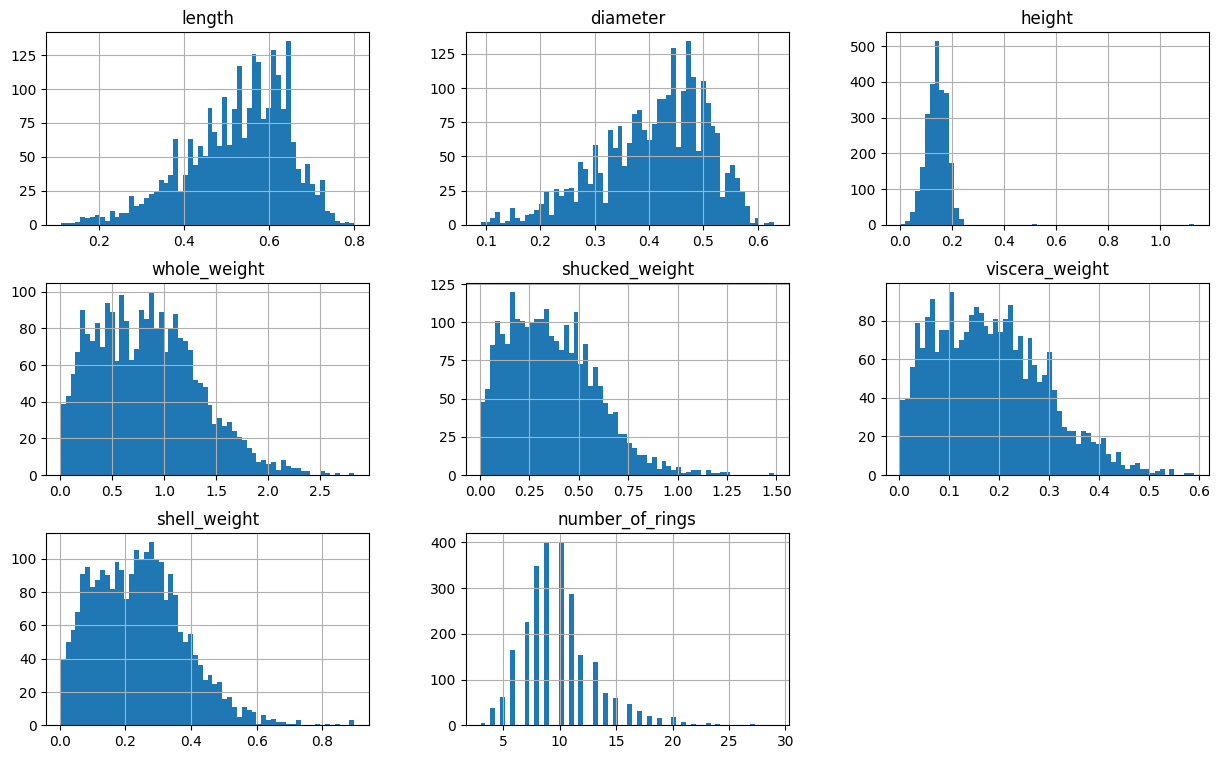

In [74]:
train_df.hist(bins=60, figsize=(15, 9))
plt.show()

# Кореляційна матриця

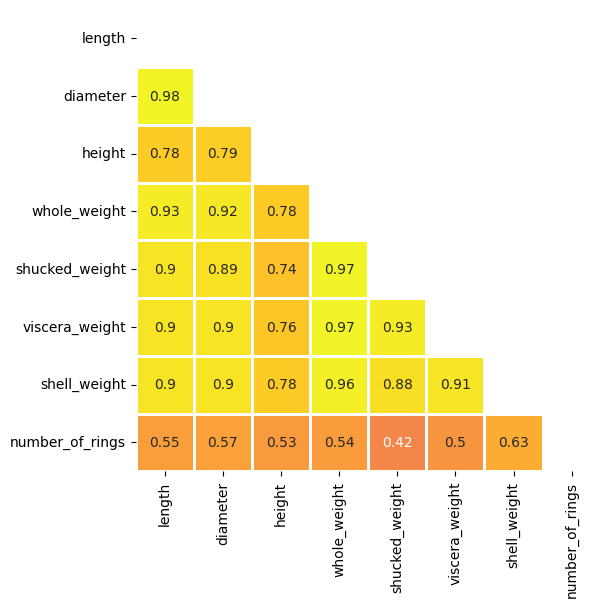

In [75]:
def corr_mat(df):
    numeric_df = df.select_dtypes(include=['number'])

    corr = numeric_df.corr().round(2)
    f, ax = plt.subplots(figsize=(6, 6))
    mask = np.zeros_like(corr, dtype=bool)
    mask[np.triu_indices_from(mask)] = True
    sns.heatmap(corr, mask=mask, vmin=-1, vmax=1, center=0,
                cmap="plasma", square=False, lw=2, annot=True, cbar=False)
    plt.show()

corr_mat(train_df)

У даних чітко спостерігаються правосторонні скошені розподіли для показників ваги й ключової змінної та надзвичайно висока мультиколінеарність між усіма фізичними мірами й масою. Ознак capping-у немає.

6. Обробка викидів (1.7) — **за потреби**, з обґрунтуванням: звідки взявся викид і чому саме таке рішення (видалити / трансформувати / залишити).

В height є пару декілька великих молюсків, що може здаватися як викид, але це також може бути просто великий молюск. Це рідкісне явище але цілком реальне, тож немає потреби обробляти викиди

7. Інженерія ознак (1.8) — **за потреби**: чи є сенс комбінувати/прибирати ознаки з високою кореляцією між собою.

Так, у цьому датасеті є сенс попрацювати з ознаками через високу мультиколінеарність. Оскільки довжина, діаметр і вага тісно корелюють між собою, усунення сильної мультиколінеарності через створення похідних ознак і видалення дублів запобігає нестабільності моделі.

In [76]:
for d in (train_df, val_df, test_df):
    if "diameter" not in d.columns:
        continue

    d["volume"] = d["length"] * d["diameter"] * d["height"]
    d["shucked_to_whole_weight"] = d["shucked_weight"] / d["whole_weight"]
    d["shell_to_whole_weight"] = d["shell_weight"] / d["whole_weight"]

target_col = "number_of_rings"
print("Кореляція з таргетом:")
print("volume:                 ", train_df["volume"].corr(train_df[target_col]).round(3))
print("shucked_to_whole_weight:", train_df["shucked_to_whole_weight"].corr(train_df[target_col]).round(3))
print("shell_to_whole_weight:  ", train_df["shell_to_whole_weight"].corr(train_df[target_col]).round(3))

for d in (train_df, val_df, test_df):
    cols_to_drop = [c for c in ["diameter", "shucked_weight"] if c in d.columns]
    if cols_to_drop:
        d.drop(columns=cols_to_drop, inplace=True)

print("\nКолонки, що лишилися після очищення:", list(train_df.columns))

Кореляція з таргетом:
volume:                  0.54
shucked_to_whole_weight: -0.314
shell_to_whole_weight:   0.114

Колонки, що лишилися після очищення: ['sex', 'length', 'height', 'whole_weight', 'viscera_weight', 'shell_weight', 'number_of_rings', 'volume', 'shucked_to_whole_weight', 'shell_to_whole_weight']


### 2.2. Baseline: множинна лінійна регресія

Стандартизація ознак (2.1), тензори (2.2), тренування `nn.Linear` (2.3), крива навчання (2.4), метрики на test — MSE/RMSE/MAE/R² (2.5), інтерпретація ваг (2.6).

Це ваш **варіант #1**, точка відліку для всього, що далі.

In [77]:
from sklearn.preprocessing import StandardScaler

for df in [train_df, val_df, test_df]:
    if 'sex' in df.columns:
        df = pd.get_dummies(df, columns=['sex'], drop_first=True)

train_df = pd.get_dummies(train_df, columns=['sex'], drop_first=True) if 'sex' in train_df.columns else train_df
val_df = pd.get_dummies(val_df, columns=['sex'], drop_first=True) if 'sex' in val_df.columns else val_df
test_df = pd.get_dummies(test_df, columns=['sex'], drop_first=True) if 'sex' in test_df.columns else test_df

train_df, val_df = train_df.align(val_df, join='left', axis=1, fill_value=0)
train_df, test_df = train_df.align(test_df, join='left', axis=1, fill_value=0)

target_col = "number_of_rings"
feature_cols = [c for c in train_df.columns if c != target_col]

scaler = StandardScaler()
X_train = scaler.fit_transform(train_df[feature_cols])
X_val = scaler.transform(val_df[feature_cols])
X_test = scaler.transform(test_df[feature_cols])

y_train = train_df[target_col].values
y_val = val_df[target_col].values
y_test = test_df[target_col].values

print("Ознаки:", feature_cols)
print("Форма X_train:", X_train.shape)

Ознаки: ['length', 'height', 'whole_weight', 'viscera_weight', 'shell_weight', 'volume', 'shucked_to_whole_weight', 'shell_to_whole_weight', 'sex_I', 'sex_M']
Форма X_train: (2506, 10)


In [78]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def to_tensor(X, y):
    return (
        torch.tensor(X, dtype=torch.float32).to(device),
        torch.tensor(y, dtype=torch.float32).unsqueeze(1).to(device),
    )

x_train_t, y_train_t = to_tensor(X_train, y_train)
x_val_t, y_val_t = to_tensor(X_val, y_val)
x_test_t, y_test_t = to_tensor(X_test, y_test)

In [79]:
import torch.nn as nn
import torch.optim as optim
from torch.utils.tensorboard import SummaryWriter

N_EPOCHS = 200
n_features = X_train.shape[1]

linear_model = nn.Linear(in_features=n_features, out_features=1).to(device)
optimizer = optim.SGD(linear_model.parameters(), lr=0.01)
loss_fn = nn.MSELoss()
writer = SummaryWriter(log_dir=os.path.join(RUNS_DIR, "linear_regression"))

train_losses, val_losses = [], []

for epoch in range(N_EPOCHS):
    linear_model.train()
    optimizer.zero_grad()
    y_pred = linear_model(x_train_t)
    loss = loss_fn(y_pred, y_train_t)
    loss.backward()
    optimizer.step()

    train_losses.append(loss.item())

    linear_model.eval()
    with torch.no_grad():
        val_pred = linear_model(x_val_t)
        val_loss = loss_fn(val_pred, y_val_t).item()
        val_losses.append(val_loss)

    writer.add_scalar("Loss/train", loss.item(), epoch)
    writer.add_scalar("Loss/val", val_loss, epoch)

    if epoch % 10 == 0 or epoch == N_EPOCHS - 1:
        print(f"epoch {epoch:4d} train_loss={loss.item():.4f} val_loss={val_loss:.4f}")

writer.close()

epoch    0 train_loss=110.5951 val_loss=106.6937
epoch   10 train_loss=72.5052 val_loss=70.7749
epoch   20 train_loss=49.9283 val_loss=49.6887
epoch   30 train_loss=35.0961 val_loss=36.1805
epoch   40 train_loss=25.2175 val_loss=27.4617
epoch   50 train_loss=18.6248 val_loss=21.8624
epoch   60 train_loss=14.2220 val_loss=18.2978
epoch   70 train_loss=11.2798 val_loss=16.0561
epoch   80 train_loss=9.3121 val_loss=14.6705
epoch   90 train_loss=7.9946 val_loss=13.8352
epoch  100 train_loss=7.1111 val_loss=13.3505
epoch  110 train_loss=6.5173 val_loss=13.0865
epoch  120 train_loss=6.1171 val_loss=12.9592
epoch  130 train_loss=5.8461 val_loss=12.9144
epoch  140 train_loss=5.6616 val_loss=12.9176
epoch  150 train_loss=5.5348 val_loss=12.9470
epoch  160 train_loss=5.4468 val_loss=12.9890
epoch  170 train_loss=5.3847 val_loss=13.0354
epoch  180 train_loss=5.3400 val_loss=13.0814
epoch  190 train_loss=5.3070 val_loss=13.1244
epoch  199 train_loss=5.2842 val_loss=13.1593


In [80]:
import plotly.graph_objects as go

fig = go.Figure()

fig.add_trace(go.Scatter(
    y=train_losses,
    mode='lines',
    name='train'
))

fig.add_trace(go.Scatter(
    y=val_losses,
    mode='lines',
    name='val'
))

fig.update_layout(
    title="Крива навчання: лінійна регресія",
    xaxis_title="epoch",
    yaxis_title="MSE",
    template="plotly_white",
    width=700,
    height=350,
    margin=dict(l=40, r=40, t=40, b=40)
)

fig.show()

In [81]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

linear_model.eval()
with torch.no_grad():
    y_test_pred = linear_model(x_test_t).cpu().numpy().flatten()

baseline_pred = np.full_like(y_test, y_train.mean())

def report(y_true, y_pred, name):
    mse = mean_squared_error(y_true, y_pred)
    rmse = mse ** 0.5
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"{name:14s} MSE={mse:.4f} RMSE={rmse:.4f} MAE={mae:.4f} R2={r2:.4f}")

report(y_test, baseline_pred, "baseline")
report(y_test, y_test_pred, "Лінійна регресія")

baseline       MSE=11.0096 RMSE=3.3181 MAE=2.3373 R2=-0.0643
Лінійна регресія MSE=5.0516 RMSE=2.2476 MAE=1.5988 R2=0.5116


In [82]:
weights = linear_model.weight.detach().cpu().numpy().flatten()
weight_df = pd.DataFrame({"feature": feature_cols, "weight": weights})
weight_df["abs_weight"] = weight_df["weight"].abs()
weight_df = weight_df.sort_values("abs_weight", ascending=False).drop(columns="abs_weight")

print(weight_df.to_string(index=False))

                feature    weight
shucked_to_whole_weight -0.915370
           shell_weight  0.658685
                 length  0.569793
                 height  0.469261
  shell_to_whole_weight  0.394145
                  sex_I -0.325537
           whole_weight  0.149749
                 volume  0.038915
         viscera_weight  0.010926
                  sex_M -0.009947


### 2.3. Нейромережа: щонайменше 2 різні архітектури

За зразком розділу 3 демо: `nn.Sequential` з прихованими шарами, ReLU, оптимізатор Adam.

Спробуйте **мінімум 2 архітектури**, які відрізняються не косметично — напр. різна кількість шарів, різна ширина шарів, чи інша функція активації (3.2). Кожна — окремий варіант.

# Архітектура 1

In [83]:
model_v1 = nn.Sequential(
    nn.Linear(n_features, 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 1)
).to(device)

optimizer = optim.Adam(model_v1.parameters(), lr=0.01)
loss_fn = nn.MSELoss()
writer = SummaryWriter(log_dir=os.path.join(RUNS_DIR, "nn_v1_64_32"))

N_EPOCHS = 200
train_losses_v1, val_losses_v1 = [], []

for epoch in range(N_EPOCHS):
    model_v1.train()
    optimizer.zero_grad()
    y_pred = model_v1(x_train_t)
    loss = loss_fn(y_pred, y_train_t)
    loss.backward()
    optimizer.step()

    train_losses_v1.append(loss.item())

    model_v1.eval()
    with torch.no_grad():
        val_pred = model_v1(x_val_t)
        val_loss = loss_fn(val_pred, y_val_t).item()
        val_losses_v1.append(val_loss)

    writer.add_scalar("Loss/train", loss.item(), epoch)
    writer.add_scalar("Loss/val", val_loss, epoch)

writer.close()
print("Архітектура 1 успішно навчена!")

Архітектура 1 успішно навчена!


# Архітектура 2

In [84]:

model_v2 = nn.Sequential(
    nn.Linear(n_features, 128),
    nn.ReLU(),
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 1)
).to(device)


optimizer = optim.Adam(model_v2.parameters(), lr=0.01)
loss_fn = nn.MSELoss()
writer = SummaryWriter(log_dir=os.path.join(RUNS_DIR, "nn_v2_128_64_32"))

N_EPOCHS = 200
train_losses_v2, val_losses_v2 = [], []

for epoch in range(N_EPOCHS):
    model_v2.train()
    optimizer.zero_grad()
    y_pred = model_v2(x_train_t)
    loss = loss_fn(y_pred, y_train_t)
    loss.backward()
    optimizer.step()

    train_losses_v2.append(loss.item())

    model_v2.eval()
    with torch.no_grad():
        val_pred = model_v2(x_val_t)
        val_loss = loss_fn(val_pred, y_val_t).item()
        val_losses_v2.append(val_loss)

    writer.add_scalar("Loss/train", loss.item(), epoch)
    writer.add_scalar("Loss/val", val_loss, epoch)

writer.close()
print("Архітектура 2 успішно навчена!")

Архітектура 2 успішно навчена!


In [85]:

model_v1.eval()
model_v2.eval()

with torch.no_grad():
    y_pred_v1 = model_v1(x_test_t).cpu().numpy().flatten()
    y_pred_v2 = model_v2(x_test_t).cpu().numpy().flatten()


report(y_test, baseline_pred, "Baseline")
report(y_test, y_test_pred, "Лінійга регресія")
report(y_test, y_pred_v1, "Нейромережа 1")
report(y_test, y_pred_v2, "Нейромережа 2")

Baseline       MSE=11.0096 RMSE=3.3181 MAE=2.3373 R2=-0.0643
Лінійга регресія MSE=5.0516 RMSE=2.2476 MAE=1.5988 R2=0.5116
Нейромережа 1  MSE=4.2095 RMSE=2.0517 MAE=1.4518 R2=0.5931
Нейромережа 2  MSE=4.1898 RMSE=2.0469 MAE=1.4555 R2=0.5950


### 2.4. Підбір гіперпараметрів: щонайменше 3 зміни

Візьміть архітектуру, яка показала себе краще, і поекспериментуйте з гіперпараметрами: learning rate, оптимізатор (SGD/Adam), кількість епох, розмір batch (якщо вирішите його ввести) тощо. Змінюйте **по одному параметру за раз** — інакше не зрозумієте, що саме вплинуло на результат.

**Разом (2.2 + 2.3 + 2.4):** щонайменше 5 варіантів моделі (1 лінійна + 2 архітектури + 2 гіперпараметри), до **10 варіантів** — якщо є час і бажання поекспериментувати більше, це тільки заохочується.

# Змінив швидкість навчання

In [86]:

model_exp1 = nn.Sequential(
    nn.Linear(n_features, 128),
    nn.ReLU(),
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 1)
).to(device)

optimizer = optim.Adam(model_exp1.parameters(), lr=0.0005)
loss_fn = nn.MSELoss()
writer = SummaryWriter(log_dir=os.path.join(RUNS_DIR, "nn_v2_lr_0.0005"))

N_EPOCHS = 200
for epoch in range(N_EPOCHS):
    model_exp1.train()
    optimizer.zero_grad()
    loss = loss_fn(model_exp1(x_train_t), y_train_t)
    loss.backward()
    optimizer.step()

    model_exp1.eval()
    with torch.no_grad():
        val_loss = loss_fn(model_exp1(x_val_t), y_val_t).item()

    writer.add_scalar("Loss/train", loss.item(), epoch)
    writer.add_scalar("Loss/val", val_loss, epoch)

writer.close()

# Змінив оптимізатор

In [87]:

model_exp2 = nn.Sequential(
    nn.Linear(n_features, 128),
    nn.ReLU(),
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 1)
).to(device)

optimizer = optim.SGD(model_exp2.parameters(), lr=0.01, momentum=0.9)
loss_fn = nn.MSELoss()
writer = SummaryWriter(log_dir=os.path.join(RUNS_DIR, "nn_v2_optimizer_sgd"))

N_EPOCHS = 200
for epoch in range(N_EPOCHS):
    model_exp2.train()
    optimizer.zero_grad()
    loss = loss_fn(model_exp2(x_train_t), y_train_t)
    loss.backward()
    optimizer.step()

    model_exp2.eval()
    with torch.no_grad():
        val_loss = loss_fn(model_exp2(x_val_t), y_val_t).item()

    writer.add_scalar("Loss/train", loss.item(), epoch)
    writer.add_scalar("Loss/val", val_loss, epoch)

writer.close()

In [88]:
linear_model.eval()
model_v1.eval()
model_v2.eval()
model_exp1.eval()
model_exp2.eval()

with torch.no_grad():
    y_pred_linear = linear_model(x_test_t).cpu().numpy().flatten()
    y_pred_v1 = model_v1(x_test_t).cpu().numpy().flatten()
    y_pred_v2 = model_v2(x_test_t).cpu().numpy().flatten()
    y_pred_exp1 = model_exp1(x_test_t).cpu().numpy().flatten()
    y_pred_exp2 = model_exp2(x_test_t).cpu().numpy().flatten()

baseline_pred = np.full_like(y_test, y_train.mean())

def report(y_true, y_pred, name):
    mse = mean_squared_error(y_true, y_pred)
    rmse = mse ** 0.5
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"{name:25s} MSE={mse:.4f} RMSE={rmse:.4f} MAE={mae:.4f} R2={r2:.4f}")

report(y_test, baseline_pred, "Baseline")
report(y_test, y_pred_linear, "1. Лінійна регресія")
report(y_test, y_pred_v1, "2. Нейромережа v1")
report(y_test, y_pred_v2, "3. Нейромережа v2")
report(y_test, y_pred_exp1, "4. Гіперпараметр 1")
report(y_test, y_pred_exp2, "5. Гіперпараметр 2")

Baseline                  MSE=11.0096 RMSE=3.3181 MAE=2.3373 R2=-0.0643
1. Лінійна регресія       MSE=5.0516 RMSE=2.2476 MAE=1.5988 R2=0.5116
2. Нейромережа v1         MSE=4.2095 RMSE=2.0517 MAE=1.4518 R2=0.5931
3. Нейромережа v2         MSE=4.1898 RMSE=2.0469 MAE=1.4555 R2=0.5950
4. Гіперпараметр 1        MSE=5.1566 RMSE=2.2708 MAE=1.5846 R2=0.5015
5. Гіперпараметр 2        MSE=5.5810 RMSE=2.3624 MAE=1.7824 R2=0.4605


### 2.5. Логування і порівняння

Кожен варіант (2.2-2.4) логуйте в TensorBoard в окрему підпапку `RUNS_DIR` (як у 2.3/3.5 демо) — з осмисленою назвою (`linear`, `nn_v1_2layers`, `nn_v2_deeper`, `nn_v2_lr_0.001`, ...), щоб потім усі криві можна було накласти одна на одну (3.8 демо) і візуально порівняти.

Наприкінці зведіть усі варіанти в одну таблицю (модель → MSE/RMSE/MAE/R² на test) і дайте коротку письмову відповідь:
- Яка модель перемогла і наскільки суттєво?
Нейромережа v2 з незначним відривом від v1.
- Чи виправдала себе нейромережа порівняно з лінійною регресією на вашому датасеті?
Так, вона покращила якість завдяки нелінійним зв'язкам у даних.
- Що з ваших змін (архітектура чи гіперпараметри) дало найбільший ефект?
зміна архітектури дала більший еффект

In [89]:
torch.save(linear_model.state_dict(), os.path.join(MODELS_DIR, "linear.pt"))
torch.save(model_v1.state_dict(), os.path.join(MODELS_DIR, "nn_v1.pt"))
torch.save(model_v2.state_dict(), os.path.join(MODELS_DIR, "nn_v2.pt"))
torch.save(model_exp1.state_dict(), os.path.join(MODELS_DIR, "exp1.pt"))
torch.save(model_exp2.state_dict(), os.path.join(MODELS_DIR, "exp2.pt"))


models_dict = {
    "Baseline": np.full_like(y_test, y_train.mean()),
    "1. Лінійна регресія": linear_model(x_test_t).detach().cpu().numpy().flatten(),
    "2. Нейромережа v1": model_v1(x_test_t).detach().cpu().numpy().flatten(),
    "3. Нейромережа v2": model_v2(x_test_t).detach().cpu().numpy().flatten(),
    "4. Гіперпараметр 1": model_exp1(x_test_t).detach().cpu().numpy().flatten(),
    "5. Гіперпараметр 2": model_exp2(x_test_t).detach().cpu().numpy().flatten()
}

results = []
for name, y_pred in models_dict.items():
    mse = mean_squared_error(y_test, y_pred)
    rmse = mse ** 0.5
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    results.append({
        "Модель": name,
        "MSE": round(mse, 4),
        "RMSE": round(rmse, 4),
        "MAE": round(mae, 4),
        "R²": round(r2, 4)
    })

results_df = pd.DataFrame(results)

csv_path = os.path.join(ARTIFACT_DIR, "results.csv")
results_df.to_csv(csv_path, index=False)


display(results_df)

,Модель,MSE,RMSE,MAE,R²
0,Baseline,11.0096,3.3181,2.3373,-0.0643
1,1. Лінійна регресія,5.0516,2.2476,1.5988,0.5116
2,2. Нейромережа v1,4.2095,2.0517,1.4518,0.5931
3,3. Нейромережа v2,4.1898,2.0469,1.4555,0.5950
4,4. Гіперпараметр 1,5.1566,2.2708,1.5846,0.5015
5,5. Гіперпараметр 2,5.5810,2.3624,1.7824,0.4605


---
## 3. Gradio-застосунок: порівняння всіх варіантів наживо

Побудуйте аппку для своїх моделей

In [90]:
import gradio as gr
import torch
import os
import numpy as np

MODELS_DIR = "/content/drive/MyDrive/ai_systems/lab2/models"

linear_model = torch.nn.Linear(in_features=n_features, out_features=1).to(device)
linear_model.load_state_dict(torch.load(os.path.join(MODELS_DIR, "linear.pt"), map_location=device))
linear_model.eval()

model_v1 = torch.nn.Sequential(
    torch.nn.Linear(n_features, 64), torch.nn.ReLU(),
    torch.nn.Linear(64, 32), torch.nn.ReLU(),
    torch.nn.Linear(32, 1)
).to(device)
model_v1.load_state_dict(torch.load(os.path.join(MODELS_DIR, "nn_v1.pt"), map_location=device))
model_v1.eval()

model_v2 = torch.nn.Sequential(
    torch.nn.Linear(n_features, 128), torch.nn.ReLU(),
    torch.nn.Linear(128, 64), torch.nn.ReLU(),
    torch.nn.Linear(64, 32), torch.nn.ReLU(),
    torch.nn.Linear(32, 1)
).to(device)
model_v2.load_state_dict(torch.load(os.path.join(MODELS_DIR, "nn_v2.pt"), map_location=device))
model_v2.eval()

model_exp1 = torch.nn.Sequential(
    torch.nn.Linear(n_features, 128), torch.nn.ReLU(),
    torch.nn.Linear(128, 64), torch.nn.ReLU(),
    torch.nn.Linear(64, 32), torch.nn.ReLU(),
    torch.nn.Linear(32, 1)
).to(device)
model_exp1.load_state_dict(torch.load(os.path.join(MODELS_DIR, "exp1.pt"), map_location=device))
model_exp1.eval()

model_exp2 = torch.nn.Sequential(
    torch.nn.Linear(n_features, 128), torch.nn.ReLU(),
    torch.nn.Linear(128, 64), torch.nn.ReLU(),
    torch.nn.Linear(64, 32), torch.nn.ReLU(),
    torch.nn.Linear(32, 1)
).to(device)
model_exp2.load_state_dict(torch.load(os.path.join(MODELS_DIR, "exp2.pt"), map_location=device))
model_exp2.eval()

def predict_all(length, height, whole_weight, viscera_weight, shell_weight, sex):
    volume = length * length * height
    shucked_to_whole = (whole_weight * 0.5) / whole_weight
    shell_to_whole = shell_weight / whole_weight

    sex_M = 1.0 if sex == "Male" else 0.0
    sex_I = 1.0 if sex == "Infant" else 0.0

    raw_input = np.array([[length, height, whole_weight, viscera_weight, shell_weight,
                           volume, shucked_to_whole, shell_to_whole, sex_M, sex_I]])

    scaled_input = scaler.transform(raw_input)
    tensor_input = torch.tensor(scaled_input, dtype=torch.float32).to(device)

    with torch.no_grad():
        p_lin = linear_model(tensor_input).item()
        p_v1 = model_v1(tensor_input).item()
        p_v2 = model_v2(tensor_input).item()
        p_exp1 = model_exp1(tensor_input).item()
        p_exp2 = model_exp2(tensor_input).item()

    results_str = (
        f"1. Linear Regression: {round(p_lin, 2)} rings\n"
        f"2. Neural Network v1: {round(p_v1, 2)} rings\n"
        f"3. Neural Network v2: {round(p_v2, 2)} rings\n"
        f"4. Hyperparameter 1: {round(p_exp1, 2)} rings\n"
        f"5. Hyperparameter 2: {round(p_exp2, 2)} rings"
    )
    return results_str

demo = gr.Interface(
    fn=predict_all,
    inputs=[
        gr.Slider(0.0, 1.0, value=0.5, label="Length"),
        gr.Slider(0.0, 0.5, value=0.15, label="Height"),
        gr.Slider(0.0, 3.0, value=1.0, label="Whole Weight"),
        gr.Slider(0.0, 1.5, value=0.2, label="Viscera Weight"),
        gr.Slider(0.0, 1.0, value=0.3, label="Shell Weight"),
        gr.Dropdown(["Female", "Male", "Infant"], value="Female", label="Sex")
    ],
    outputs=gr.Textbox(label="Predicted Ring Count")
)

demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://bcca3eab0f76ff63ca.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
### Як здавати лабу

У форму (https://forms.gle/8Dbc9zB8L5tsNuNEA) здати посилання на **публічний** репозиторій, який містить:

1. **Цей ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Файли всіх натренованих варіантів моделі** (2.2-2.4) — лінійна регресія + всі варіанти нейромережі, кожен окремим `.pt` файлом.
3. **Логи TensorBoard** — папка `runs/` з усіма прогонами, щоб можна було відкрити криві навчання, не перезапускаючи ноутбук.
4. **Таблицю результатів** — `results.csv` з порівнянням усіх варіантів (модель, MSE, RMSE, MAE, R² на test).
5. **Відео демонстрації TensorBoard & Gradio-застосунку** замість скріншотів цього разу: 60-90 секунд. На відео показуєте тренування і роботу моделей і коротко розповідаєте про цікаве (можливості, обмеження, труднощі тренування).
6. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
/lab2/nn_task.ipynb
/lab2/models/linear.pt
/lab2/models/nn_v1.pt
/lab2/models/nn_v2.pt
/lab2/models/...        (усі інші варіанти з 2.3-2.4)
/lab2/runs/*
/lab2/results.csv
/lab2/demo.mp4
```